In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("hockey_teams_raw.csv")
print("    INFO of DATASET")
print("shape of dataset")
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}")
print()
print("data types of columns")
print(df.dtypes)
print()
print(" Missing Values")
missing_df = pd.DataFrame({"Missing Count":df.isnull().sum(),"Missing %":(df.isnull().mean()*100).round(3)})
print(missing_df)
print()
print("   Exact Duplicates ")
cols_to_check = df.columns.drop("collected_at")
print("Duplicate rows:",cols_to_check)
print()
print("    Summary Statistics")
print(df.describe())


    INFO of DATASET
shape of dataset
Total Rows: 582, Total Columns: 10

data types of columns
Team Name           str
Year              int64
Wins              int64
Losses            int64
OT Losses       float64
Win %           float64
GF                int64
GA                int64
+/-               int64
collected_at        str
dtype: object

 Missing Values
              Missing Count  Missing %
Team Name                 0      0.000
Year                      0      0.000
Wins                      0      0.000
Losses                    0      0.000
OT Losses               224     38.488
Win %                     0      0.000
GF                        0      0.000
GA                        0      0.000
+/-                       0      0.000
collected_at              0      0.000

   Exact Duplicates 
Duplicate rows: Index(['Team Name', 'Year', 'Wins', 'Losses', 'OT Losses', 'Win %', 'GF', 'GA',
       '+/-'],
      dtype='str')

    Summary Statistics
              Year        Win

1. It loads the csv file we fetched from the website and displays all the information about it
2. It inspects raw data's integrity before we do actual work on it
3. The dataset contains 582 rows and 10 cols. It also tells each column's data type,number of missing values, number of duplicated rows and basic description of the data like mean, median, count etc.

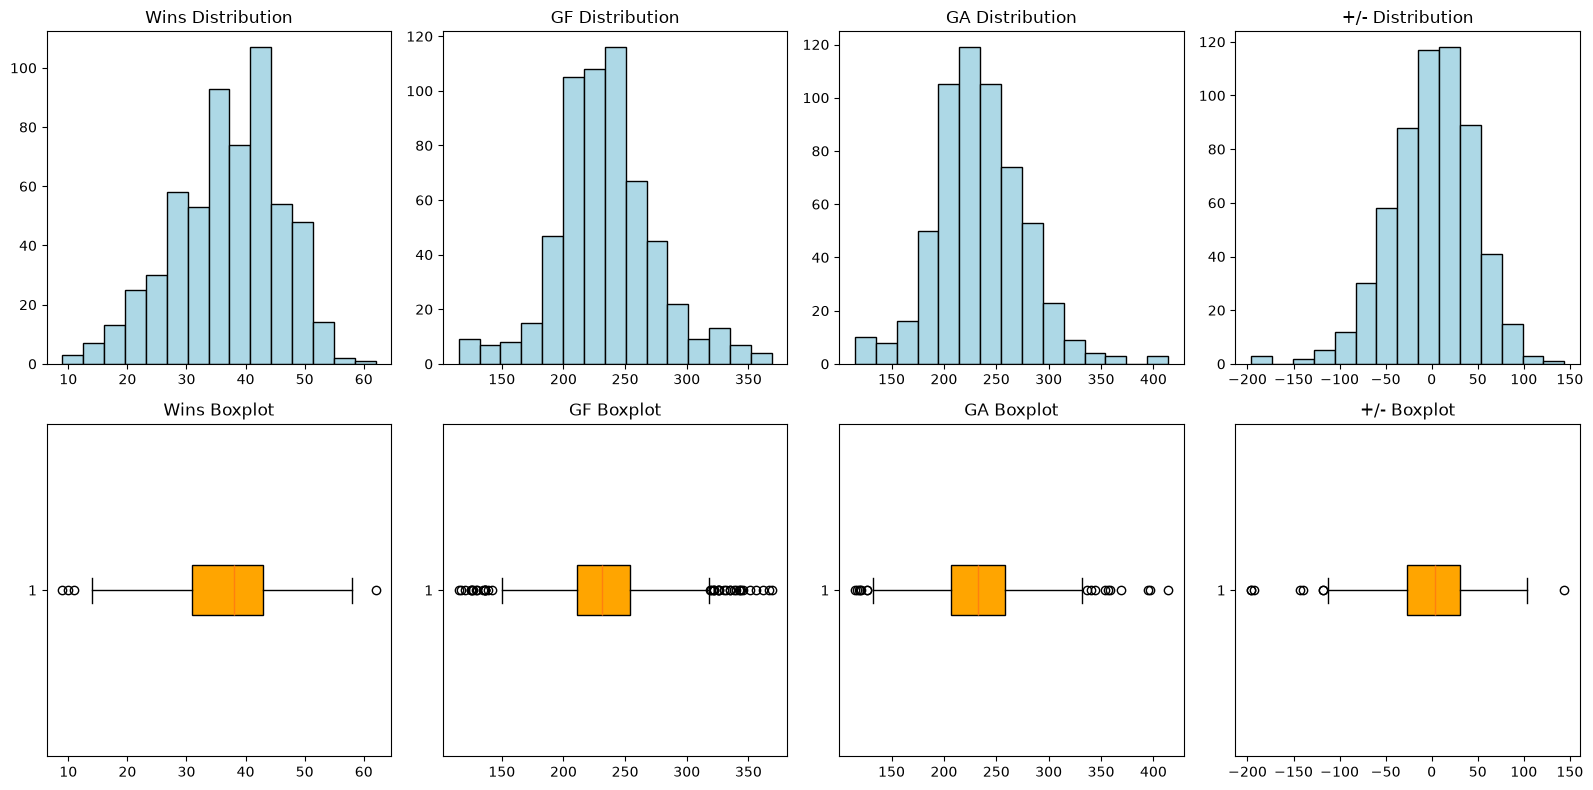

   Skewness Before Transformation
Wins   -0.39
GF      0.25
GA      0.32
+/-    -0.58
dtype: float64

    Skewness Comparison: Before vs After log1p
    Before Skewness  After log1p Skewness
GF             0.25                 -0.63
GA             0.32                 -0.53


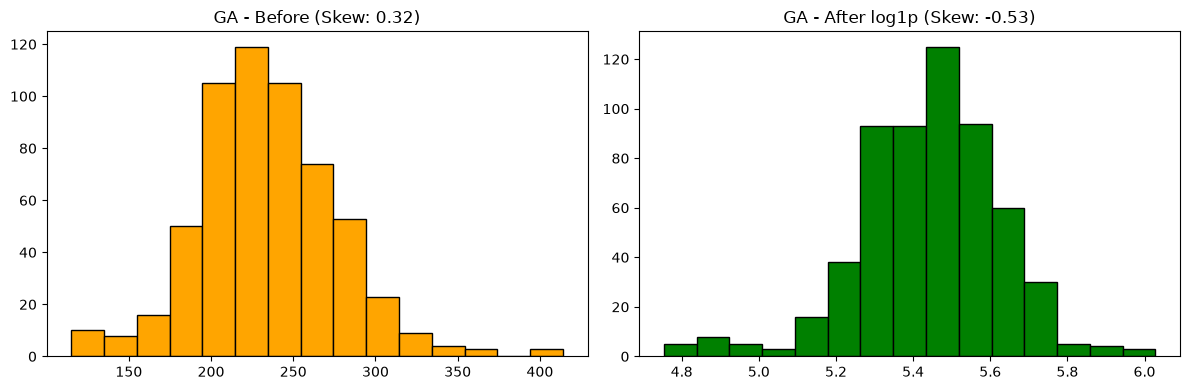

In [2]:
numerical_cols=["Wins","GF","GA","+/-",]
fig, axes = plt.subplots(2, len(numerical_cols), figsize=(16, 8))
for i, col in enumerate(numerical_cols):
    # Top row is for Histogram graphs
    axes[0,i].hist(df[col].dropna(),bins=15,color="lightblue",edgecolor="black")
    axes[0, i].set_title(f"{col} Distribution")
    # Bottom row: for Boxplot graph's
    axes[1,i].boxplot(df[col].dropna(),orientation="horizontal",patch_artist=True,boxprops=dict(facecolor="orange"))
    axes[1, i].set_title(f"{col} Boxplot")
plt.tight_layout() # for adjusting space btw graphs
plt.show() #for displaying graphs
print("   Skewness Before Transformation")
skewness_before = df[numerical_cols].skew()
print(skewness_before.round(2))
print()
positive_col = ["GF", "GA"]
skewness_check = df[positive_col].copy()
for col in positive_col:       #normalizing the outliers
    skewness_check[f"{col}_log1p"] = np.log1p(skewness_check[col])
print("    Skewness Comparison: Before vs After log1p")
comparison = pd.DataFrame({
    "Before Skewness": [df["GF"].skew(), df["GA"].skew()],
    "After log1p Skewness": [skewness_check["GF_log1p"].skew(), skewness_check["GA_log1p"].skew()]}, index=positive_col)
print(comparison.round(2))
most_skewed = comparison["Before Skewness"].abs().idxmax()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df[most_skewed].dropna(), bins=15, color="orange",edgecolor="black")
axes[0].set_title(f"{most_skewed} - Before (Skew: {df[most_skewed].skew():.2f})")

axes[1].hist(skewness_check[f"{most_skewed}_log1p"].dropna(), bins=15, color="green",edgecolor='black')
axes[1].set_title(f"{most_skewed} - After log1p (Skew: {skewness_check[f'{most_skewed}_log1p'].skew():.2f})")
plt.tight_layout()
plt.show()

1. This part of code generates histogram and boxplot for specified columns in the code and also display there skewness and the change in graphs before and after skewness
2. This is done inorder to find the skewness and the outliers for each columns abhi or likhna hai
3. histograms and boxplot for each columns thier skewness and change in the graphs before and after skewness